In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector


from sims import run_experiment, build_circuit, check_circuit,estimate_logical_error_rate
from collections import defaultdict
import json

In [6]:
result = run_experiment(config_filepath="config/5x3.json", max_shots=200_000, seed=1)
print(result)

shots: 200000
logical error rate (any logical): 0.06847  [95% CI 0.06737, 0.06959]  (13694 failures)
  Z logical: 0.02767  (5534 failures)
  X logical: 0.0458  (9159 failures)


Post-selection uses the same circuit as the cell above. It samples 200,000 shots with `compile_detector_sampler(seed=1)` and `separate_observables=True`.

- A shot is rejected when any detector is 1, including detectors from the final readout.
- A shot is accepted when every detector is 0.
- An accepted shot is a logical error when its sampled observable is 1. There is no correction. Z is observable 0 and X is observable 1, as in `build_circuit`.


In [11]:
from sims import wilson_interval

c = build_circuit(config_filepath="config/5x3.json")
shots = 200_000_000
dets, obs = c.compile_detector_sampler(seed=1).sample(shots, separate_observables=True)

accepted = ~dets.any(axis=1)
n_accepted = int(accepted.sum())
n_rejected = shots - n_accepted
acceptance = n_accepted / shots
rejection = n_rejected / shots
acc_lo, acc_hi = wilson_interval(n_accepted, shots)

print(f"shots: {shots}")
print(f"accepted: {n_accepted}  rejected: {n_rejected}")
print(f"acceptance rate: {acceptance:.4g}  [95% CI {acc_lo:.4g}, {acc_hi:.4g}]")
print(f"rejection rate: {rejection:.4g}")

if n_accepted == 0:
    print("no shots accepted")
else:
    kept = obs[accepted]
    labels = ("Z", "X", "either")
    counts = [
        int(kept[:, 0].sum()),
        int(kept[:, 1].sum()),
        int(kept.any(axis=1).sum()),
    ]
    for label, k in zip(labels, counts):
        lo, hi = wilson_interval(k, n_accepted)
        print(
            f"  {label} logical error rate among accepted: {k / n_accepted:.4g}"
            f"  [95% CI {lo:.4g}, {hi:.4g}]  ({k} failures)"
        )


shots: 200000000
accepted: 146646726  rejected: 53353274
acceptance rate: 0.7332  [95% CI 0.7332, 0.7333]
rejection rate: 0.2668
  Z logical error rate among accepted: 0.002015  [95% CI 0.002007, 0.002022]  (295450 failures)
  X logical error rate among accepted: 0.007711  [95% CI 0.007697, 0.007726]  (1130845 failures)
  either logical error rate among accepted: 0.008857  [95% CI 0.008842, 0.008872]  (1298817 failures)


In [3]:
c = build_circuit(config_filepath="config/5x3.json", error_model="error_model.json")
check_circuit(c)

# expected faults per shot
dem = c.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True,
                             ignore_decomposition_failures=True)
print("expected faults/shot:", sum(i.args_copy()[0] for i in dem.flattened() if i.type == "error"))

# smallest set of faults that flips a logical with no detection event
print(len(c.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=4,
    dont_explore_edges_with_degree_above=3,
    dont_explore_edges_increasing_symptom_degree=False)))

expected faults/shot: 0.3171944441889735
1


In [4]:
c = build_circuit(config_filepath="config/5x3.json", error_model="error_model.json")

# 1. the shortest one, with its location in the circuit
errs = c.search_for_undetectable_logical_errors(
    dont_explore_detection_event_sets_with_size_above=4,
    dont_explore_edges_with_degree_above=3,
    dont_explore_edges_increasing_symptom_degree=False)
print(errs[0])

# 2. all single faults with no detection events, and their total probability
dem = c.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True, ignore_decomposition_failures=True)
undetected = [i for i in dem.flattened()
              if i.type == "error"
              and not any(t.is_relative_detector_id() for t in i.targets_copy())]
print(len(undetected), "mechanisms, total p =", sum(i.args_copy()[0] for i in undetected))

# 3. where each one comes from
bad = stim.DetectorErrorModel()
for i in undetected:
    bad.append(i)
for e in c.explain_detector_error_model_errors(dem_filter=bad, reduce_to_one_representative_error=True):
    print(e.dem_error_terms, "<-", e.circuit_error_locations[0])

ExplainedError {
    dem_error_terms: L1
    CircuitErrorLocation {
        flipped_pauli_product: Y20[coords 2,0.5]*Z8[coords 2,1]
        Circuit location stack trace:
            (after 9 TICKs)
            at instruction #82 (DEPOLARIZE2) in the circuit
            at targets #3 to #4 of the instruction
            resolving to DEPOLARIZE2(0.001) 20[coords 2,0.5] 8[coords 2,1]
    }
    CircuitErrorLocation {
        flipped_pauli_product: Z20[coords 2,0.5]*Z8[coords 2,1]
        Circuit location stack trace:
            (after 9 TICKs)
            at instruction #82 (DEPOLARIZE2) in the circuit
            at targets #3 to #4 of the instruction
            resolving to DEPOLARIZE2(0.001) 20[coords 2,0.5] 8[coords 2,1]
    }
    CircuitErrorLocation {
        flipped_pauli_product: Z8[coords 2,1]
        Circuit location stack trace:
            (after 8 TICKs)
            at instruction #79 (DEPOLARIZE1) in the circuit
            at target #4 of the instruction
            resolv

In [5]:
base = json.load(open("error_model.json"))
for scale in (1, 0.5, 0.25):
    m = {k: (v * scale if k.startswith("p_") else v) for k, v in base.items()}
    json.dump(m, open("tmp_model.json", "w"))
    r = run_experiment(config_filepath="config/5x3.json", error_model="tmp_model.json", max_shots=200_000, seed=1)
    print(scale, r.logical_error_rate)

1 0.06653
0.5 0.03323
0.25 0.016695


In [4]:
c = build_circuit(config_filepath="config/5x3.json", error_model="error_model.json")
dem = c.detector_error_model(decompose_errors=True, approximate_disjoint_errors=True, ignore_decomposition_failures=True)

clean = stim.DetectorErrorModel()
for i in dem.flattened():
    if i.type == "error" and not any(t.is_relative_detector_id() for t in i.targets_copy()):
        continue                      # skip the undetectable injection faults
    clean.append(i)

path = clean.shortest_graphlike_error()
print("effective distance:", len(path))
for e in c.explain_detector_error_model_errors(dem_filter=path, reduce_to_one_representative_error=True):
    print(e.dem_error_terms, "<-", e.circuit_error_locations[0])

effective distance: 2
[stim.DemTargetWithCoords(dem_target=stim.DemTarget('D0'), coords=[1.75, 0, 5]), stim.DemTargetWithCoords(dem_target=stim.DemTarget('D1'), coords=[2.5, 0, 5])] <- CircuitErrorLocation {
    flipped_pauli_product: X4[coords 3,0]
    Circuit location stack trace:
        (after 0 TICKs)
        at instruction #39 (X_ERROR) in the circuit
        at target #4 of the instruction
        resolving to X_ERROR(0.001) 4[coords 3,0]
}
[stim.DemTargetWithCoords(dem_target=stim.DemTarget('D0'), coords=[1.75, 0, 5]), stim.DemTargetWithCoords(dem_target=stim.DemTarget('D1'), coords=[2.5, 0, 5]), stim.DemTargetWithCoords(dem_target=stim.DemTarget('L0'), coords=[])] <- CircuitErrorLocation {
    flipped_pauli_product: X3[coords 2,0]
    Circuit location stack trace:
        (after 0 TICKs)
        at instruction #39 (X_ERROR) in the circuit
        at target #3 of the instruction
        resolving to X_ERROR(0.001) 3[coords 2,0]
}


In [7]:
dem = c.detector_error_model(approximate_disjoint_errors=True)   # no decomposition: ideal decoder

groups = defaultdict(lambda: defaultdict(float))   # syndrome -> {observable set -> total p}
for inst in dem.flattened():
    if inst.type != "error":
        continue
    p = inst.args_copy()[0]
    ts = inst.targets_copy()
    dets = frozenset(t.val for t in ts if t.is_relative_detector_id())
    obs = frozenset(t.val for t in ts if t.is_logical_observable_id())
    groups[dets][obs] += p

predicted = 0.0
for dets, classes in groups.items():
    if not dets:                       # undetectable: only the no-flip outcome is benign
        predicted += sum(p for o, p in classes.items() if o)
    else:                              # decoder picks the most likely class; the rest are failures
        predicted += sum(classes.values()) - max(classes.values())
print("first-order prediction of failure rate:", predicted)

first-order prediction of failure rate: 0.058869246044569654


In [8]:
def first_order(c):
    from collections import defaultdict
    dem = c.detector_error_model(approximate_disjoint_errors=True)
    g = defaultdict(lambda: defaultdict(float))
    for i in dem.flattened():
        if i.type != "error": continue
        ts = i.targets_copy()
        d = frozenset(t.val for t in ts if t.is_relative_detector_id())
        o = frozenset(t.val for t in ts if t.is_logical_observable_id())
        g[d][o] += i.args_copy()[0]
    return sum(
        sum(p for o, p in cl.items() if o) if not d else sum(cl.values()) - max(cl.values())
        for d, cl in g.items()
    )

base = json.load(open("error_model.json"))
for scale in (1, 0.5, 0.25, 0.1):
    m = {k: (v * scale if k.startswith("p_") else v) for k, v in base.items()}
    json.dump(m, open("tmp_model.json", "w"))
    c = build_circuit(config_filepath="config/5x3.json", error_model="tmp_model.json")
    r = estimate_logical_error_rate(c, max_shots=400_000, seed=1)
    pred = first_order(c)
    print(f"scale {scale}: measured {r.logical_error_rate:.4f}  predicted {pred:.4f}  ratio {r.logical_error_rate / pred:.2f}")

scale 1: measured 0.0669  predicted 0.0589  ratio 1.14
scale 0.5: measured 0.0334  predicted 0.0295  ratio 1.13
scale 0.25: measured 0.0169  predicted 0.0148  ratio 1.14
scale 0.1: measured 0.0065  predicted 0.0059  ratio 1.10


In [9]:
from sims import *

c = build_circuit(config_filepath="config/5x3.json", error_model="error_model.json")
m = build_matching(c)

rate, worst = first_order_failure_rate(c, m, top=10)
print("first-order failure rate of this decoder:", rate)      # compare with 0.0589 ideal, 0.1087 measured
for p, s in worst:
    print(f"{p:.2e}  {s}")

mc = build_matching(c, correlated=True)
print("correlated, first-order:", first_order_failure_rate(c, mc, correlated=True)[0])
print(estimate_logical_error_rate(c, mc, max_shots=200_000, seed=1, correlated=True))

first-order failure rate of this decoder: 0.06639543130347583
8.34e-03  D[10] L[0]
7.15e-03  D[15] L[0]
6.69e-03  D[9] L[1]
6.30e-03  D[] L[1]
5.24e-03  D[7] L[]
5.24e-03  D[8] L[1]
4.25e-03  D[13] L[1]
2.26e-03  D[12] L[]
2.20e-03  D[9, 10] L[0]
1.93e-03  D[2] L[0]
correlated, first-order: 0.11623742232085651
shots: 200000
logical error rate (any logical): 0.1077  [95% CI 0.1064, 0.1091]  (21544 failures)
  Z logical: 0.06412  (12823 failures)
  X logical: 0.0499  (9980 failures)


## Logical error rate versus physical error rate

Every probability in the error model is set to the same value of `p`, at six evenly spaced points from `0.001` to `0.006`. Each point is 200,000 post-selected shots of the 4-round circuit. A shot is kept only when every detector is 0, and a kept shot is a logical error when either observable is 1.

The dashed line is a straight-line least-squares fit to the measured logical error rates.


p=0.001  acceptance=0.8922  either=0.003105  Z=0.0009863  X=0.00255  first-order=0.002931
p=0.002  acceptance=0.7955  either=0.006493  Z=0.001986  X=0.005393  first-order=0.005858
p=0.003  acceptance=0.7075  either=0.009513  Z=0.002827  X=0.007838  first-order=0.00878
p=0.004  acceptance=0.6336  either=0.01356  Z=0.004482  X=0.01119  first-order=0.0117
p=0.005  acceptance=0.5681  either=0.01737  Z=0.005431  X=0.01435  first-order=0.01461
p=0.006  acceptance=0.5078  either=0.02213  Z=0.006862  X=0.01843  first-order=0.01752
p=0.007  acceptance=0.4534  either=0.02563  Z=0.007918  X=0.02116  first-order=0.02042
p=0.008  acceptance=0.4051  either=0.03101  Z=0.009468  X=0.02529  first-order=0.02332
p=0.009  acceptance=0.3655  either=0.03448  Z=0.01029  X=0.02832  first-order=0.02622
p=0.01  acceptance=0.3273  either=0.04106  Z=0.0124  X=0.03386  first-order=0.02911
p=0.011  acceptance=0.2938  either=0.04503  Z=0.01395  X=0.03647  first-order=0.03199
p=0.012  acceptance=0.2627  either=0.0500

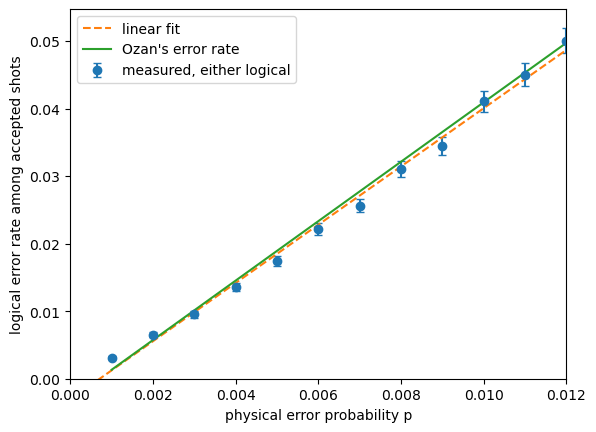

In [34]:
import json
from sims import wilson_interval

base = json.load(open("error_model.json"))
p_values = np.linspace(0.001, 0.012, 12)
shots = 200_000

rows = []
for p in p_values:
    model = {k: (float(p) if k.startswith("p_") else v) for k, v in base.items()}
    json.dump(model, open("tmp_model.json", "w"))
    circuit = build_circuit(config_filepath="config/5x3.json", error_model="tmp_model.json")
    dets, obs = circuit.compile_detector_sampler(seed=1).sample(
        shots, separate_observables=True
    )

    accepted = ~dets.any(axis=1)
    n_accepted = int(accepted.sum())
    acceptance = n_accepted / shots

    first_order = 0.0
    dem = circuit.detector_error_model(approximate_disjoint_errors=True)
    for inst in dem.flattened():
        if inst.type != "error":
            continue
        targets = inst.targets_copy()
        if any(t.is_relative_detector_id() for t in targets):
            continue
        if any(t.is_logical_observable_id() for t in targets):
            first_order += inst.args_copy()[0]

    if n_accepted == 0:
        rate = z_rate = x_rate = np.nan
        lo, hi = 0.0, 1.0
        print(f"p={p:.4g}  acceptance={acceptance:.4g}  no shots accepted  first-order={first_order:.4g}")
    else:
        kept = obs[accepted]
        k_z = int(kept[:, 0].sum())
        k_x = int(kept[:, 1].sum())
        k_either = int(kept.any(axis=1).sum())
        z_rate = k_z / n_accepted
        x_rate = k_x / n_accepted
        rate = k_either / n_accepted
        lo, hi = wilson_interval(k_either, n_accepted)
        print(
            f"p={p:.4g}  acceptance={acceptance:.4g}  "
            f"either={rate:.4g}  Z={z_rate:.4g}  X={x_rate:.4g}  "
            f"first-order={first_order:.4g}"
        )

    rows.append((p, acceptance, rate, lo, hi, z_rate, x_rate, first_order))

ps, acceptances, rates, los, his, z_rates, x_rates, first_orders = map(np.array, zip(*rows))


lower = np.maximum(rates - los, 0)
upper = np.maximum(his - rates, 0)
ok = np.isfinite(rates)
slope, intercept = np.polyfit(ps[ok], rates[ok], 1)
print(f"linear fit: rate = {slope:.4g} p + {intercept:.4g}")
p_line = np.array([0.0, 0.012])
plt.errorbar(ps, rates, yerr=[lower, upper], fmt="o", capsize=3, label="measured, either logical")
plt.plot(p_line, slope * p_line + intercept, "--", label="linear fit")
plt.xlim(0, 0.012)
plt.ylim(bottom=0)
plt.plot(ps, ps*4.4 + intercept, label="Ozan's error rate")
plt.xlabel("physical error probability p")
plt.ylabel("logical error rate among accepted shots")
plt.legend()


plt.show()
